In [ ]:

# ============================================================
# ALERTWAVE - PART 1: SETUP AND DATASET DOWNLOAD
# ============================================================

!pip -q install librosa soundfile scikit-learn

import os
import json
import zipfile
import warnings
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Project folders
PROJECT_DIR = Path("/content/AlertWave")
DATA_DIR = PROJECT_DIR / "dataset"
EXTRACT_DIR = DATA_DIR / "extracted"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

# Dataset URLs
ZIP_URL = (
    "https://zenodo.org/records/4319802/files/"
    "DATASET_AOB.zip?download=1"
)

METADATA_URL = (
    "https://zenodo.org/records/4319802/files/"
    "metadata_Dataset-AOB.csv?download=1"
)

ZIP_PATH = DATA_DIR / "DATASET_AOB.zip"
METADATA_PATH = DATA_DIR / "metadata_Dataset-AOB.csv"

# Download dataset only if it is not already present
if not ZIP_PATH.exists():
    print("Downloading AlertWave dataset...")
    !wget -c -O /content/AlertWave/dataset/DATASET_AOB.zip "https://zenodo.org/records/4319802/files/DATASET_AOB.zip?download=1"
else:
    print("Dataset ZIP already exists.")

if not METADATA_PATH.exists():
    print("Downloading metadata...")
    !wget -O /content/AlertWave/dataset/metadata_Dataset-AOB.csv "https://zenodo.org/records/4319802/files/metadata_Dataset-AOB.csv?download=1"
else:
    print("Metadata already exists.")

# Extract dataset
if not any(EXTRACT_DIR.rglob("*.wav")):
    print("Extracting dataset. This may take some time...")

    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

    print("Extraction completed.")
else:
    print("Audio files already extracted.")

# ============================================================
# CLASS ORDER - DO NOT CHANGE THIS ORDER
# ============================================================

CLASSES = [
    "alarm_siren",
    "children_playing",
    "dog_bark",
    "engine",
    "footsteps",
    "glass_breaking",
    "gun_shot",
    "metro_train",
    "rain",
    "screams"
]

CLASS_TO_INDEX = {
    name: index
    for index, name in enumerate(CLASSES)
}

print("\nAlertWave classes:")
for index, name in enumerate(CLASSES):
    print(index, ":", name)

# ============================================================
# READ DATASET METADATA
# ============================================================

metadata = pd.read_csv(METADATA_PATH)

# The metadata uses blank labels for additional folders
metadata["label"] = metadata["label"].ffill()

metadata = metadata.dropna(subset=["folder", "label"])

metadata["folder"] = metadata["folder"].astype(str).str.strip()
metadata["label"] = metadata["label"].astype(str).str.strip()

folder_to_label = {}

for _, row in metadata.iterrows():

    folder_name = row["folder"]
    label = row["label"]

    if label in CLASS_TO_INDEX:
        folder_to_label[folder_name] = label

print("\nMetadata folder mappings:")
for folder, label in folder_to_label.items():
    print(folder, "->", label)

# ============================================================
# FIND AUDIO FILES AND ASSIGN LABELS
# ============================================================

audio_records = []

for audio_path in EXTRACT_DIR.rglob("*"):

    if audio_path.suffix.lower() not in [".wav"]:
        continue

    matching_folder = None

    for folder_part in audio_path.parts:
        if folder_part in folder_to_label:
            matching_folder = folder_part
            break

    if matching_folder is None:
        continue

    label = folder_to_label[matching_folder]

    audio_records.append({
        "path": str(audio_path),
        "label": label,
        "class_index": CLASS_TO_INDEX[label]
    })

dataset_df = pd.DataFrame(audio_records)

if dataset_df.empty:
    raise RuntimeError(
        "No labelled WAV files were found. "
        "Check the extracted folder structure and metadata."
    )

print("\nTotal labelled audio files:", len(dataset_df))
print("\nClass distribution:")
print(
    dataset_df["label"]
    .value_counts()
    .reindex(CLASSES, fill_value=0)
)

missing_classes = [
    c for c in CLASSES
    if dataset_df["label"].eq(c).sum() == 0
]

if missing_classes:
    raise RuntimeError(
        f"Missing classes in extracted dataset: {missing_classes}"
    )

print("\nPart 1 completed successfully.")


--2026-11-16 03:26:39--  https://zenodo.org/records/4319802/files/DATASET_AOB.zip?download=1
Resolving zenodo.org (zenodo.org)... 137.138.121.78, 188.185.51.60, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|137.138.121.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1739260800 (1.6G) [application/octet-stream]
Saving to: ‘/content/AlertWave/dataset/DATASET_AOB.zip’

/content/AlertWave/ 100%[===================>]   1.62G  3.19MB/s    in 10m 36s 

2026-11-16 03:37:15 (2.61 MB/s) - ‘/content/AlertWave/dataset/DATASET_AOB.zip’ saved [1739260800/1739260800]

--2026-11-16 03:37:15--  https://zenodo.org/records/4319802/files/metadata_Dataset-AOB.csv?download=1
Resolving zenodo.org (zenodo.org)... 188.185.47.192, 188.185.51.60, 188.185.42.113, ...
Connecting to zenodo.org (zenodo.org)|188.185.47.192|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 819 [text/plain]
Saving to: ‘/content/AlertWave/dataset/metadata_Dataset-AOB.csv’


In [ ]:

# ============================================================
# ALERTWAVE - PART 2: AUDIO PREPROCESSING
# ============================================================

SAMPLE_RATE = 22050
DURATION = 4.0
N_MELS = 128
MAX_FRAMES = 128

N_FFT = 1024
HOP_LENGTH = 512

def preprocess_audio_path(audio_path):

    audio, sr = librosa.load(
        audio_path,
        sr=SAMPLE_RATE,
        mono=True,
        duration=DURATION
    )

    required_samples = int(SAMPLE_RATE * DURATION)

    if len(audio) < required_samples:
        audio = np.pad(
            audio,
            (0, required_samples - len(audio))
        )
    else:
        audio = audio[:required_samples]

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # Keep exactly MAX_FRAMES
    if mel_db.shape[1] < MAX_FRAMES:
        mel_db = np.pad(
            mel_db,
            (
                (0, 0),
                (0, MAX_FRAMES - mel_db.shape[1])
            )
        )
    else:
        mel_db = mel_db[:, :MAX_FRAMES]

    # Normalize to a fixed range
    mel_db = np.clip(
        (mel_db + 80.0) / 80.0,
        0.0,
        1.0
    )

    return mel_db.astype(np.float32)


# ============================================================
# CONVERT AUDIO FILES TO MEL SPECTROGRAMS
# ============================================================

X = []
y = []
failed_files = []

print("Converting audio files to spectrograms...")

for index, row in dataset_df.iterrows():

    try:
        features = preprocess_audio_path(row["path"])

        X.append(features)
        y.append(row["class_index"])

    except Exception as error:
        failed_files.append((row["path"], str(error)))

    if (len(X) + len(failed_files)) % 200 == 0:
        print(
            "Processed:",
            len(X) + len(failed_files),
            "/",
            len(dataset_df)
        )

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)

# CNN input shape: samples x mel x frames x channels
X = np.expand_dims(X, axis=-1)

print("\nFeature array shape:", X.shape)
print("Label array shape:", y.shape)
print("Failed files:", len(failed_files))

if len(X) == 0:
    raise RuntimeError("No audio files could be processed.")

# ============================================================
# TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print("\nTraining samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

# ============================================================
# CLASS BALANCING
# ============================================================

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = {
    int(class_index): float(weight)
    for class_index, weight in zip(
        np.unique(y_train),
        class_weights_array
    )
}

print("\nClass weights:")
for class_index, weight in class_weights.items():
    print(CLASSES[class_index], ":", round(weight, 3))

# ============================================================
# CNN MODEL
# ============================================================

from tensorflow.keras import layers, models, regularizers

input_shape = (N_MELS, MAX_FRAMES, 1)

inputs = layers.Input(shape=input_shape)

# Mild training-time augmentation
x = layers.GaussianNoise(0.025)(inputs)

x = layers.RandomTranslation(
    height_factor=0.0,
    width_factor=0.06,
    fill_mode="nearest"
)(x)

# CNN block 1
x = layers.Conv2D(
    32,
    (3, 3),
    padding="same",
    kernel_regularizer=regularizers.l2(0.001)
)(x)

x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# CNN block 2
x = layers.Conv2D(
    64,
    (3, 3),
    padding="same",
    kernel_regularizer=regularizers.l2(0.001)
)(x)

x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# CNN block 3
x = layers.Conv2D(
    128,
    (3, 3),
    padding="same",
    kernel_regularizer=regularizers.l2(0.001)
)(x)

x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(
    128,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.001)
)(x)

x = layers.Dropout(0.40)(x)

outputs = layers.Dense(
    len(CLASSES),
    activation="softmax"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs,
    name="AlertWave_CNN"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ============================================================
# TRAINING CALLBACKS
# ============================================================

MODEL_PATH = str(PROJECT_DIR / "alertwave_cnn.keras")

callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=0.00001,
        verbose=1
    )
]

# ============================================================
# TRAIN CNN
# ============================================================

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

# Load best checkpoint
model = tf.keras.models.load_model(MODEL_PATH)

print("\nCNN training completed.")


Converting audio files to spectrograms...
Processed: 200 / 4831
Processed: 400 / 4831
Processed: 600 / 4831
Processed: 800 / 4831
Processed: 1000 / 4831
Processed: 1200 / 4831
Processed: 1400 / 4831
Processed: 1600 / 4831
Processed: 1800 / 4831
Processed: 2000 / 4831
Processed: 2200 / 4831
Processed: 2400 / 4831
Processed: 2600 / 4831
Processed: 2800 / 4831
Processed: 3000 / 4831
Processed: 3200 / 4831
Processed: 3400 / 4831
Processed: 3600 / 4831
Processed: 3800 / 4831
Processed: 4000 / 4831
Processed: 4200 / 4831
Processed: 4400 / 4831
Processed: 4600 / 4831
Processed: 4800 / 4831

Feature array shape: (4831, 128, 128, 1)
Label array shape: (4831,)
Failed files: 0

Training samples: 3091
Validation samples: 773
Testing samples: 967

Class weights:
alarm_siren : 1.444
children_playing : 0.473
dog_bark : 1.041
engine : 1.593
footsteps : 1.007
glass_breaking : 1.283
gun_shot : 0.984
metro_train : 0.635
rain : 1.593
screams : 1.627


Model: "AlertWave_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise (GaussianNoise)  │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 128, 128, 1)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,370 (435.04 KB)

 Trainable params: 110,922 (433.29 KB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.2011 - loss: 2.4308
Epoch 1: val_loss improved from None to 2.60859, saving model to /content/AlertWave/alertwave_cnn.keras

Epoch 1: finished saving model to /content/AlertWave/alertwave_cnn.keras
97/97 ━━━━━━━━━━━━━━━━━━━━ 14s 61ms/step - accuracy: 0.2643 - loss: 2.2368 - val_accuracy: 0.1048 - val_loss: 2.6086 - learning_rate: 5.0000e-04
Epoch 2/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.4023 - loss: 1.9174
Epoch 2: val_loss did not improve from 2.60859
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.4264 - loss: 1.8495 - val_accuracy: 0.0621 - val_loss: 3.1446 - learning_rate: 5.0000e-04
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.4996 - loss: 1.6949
Epoch 3: val_loss did not improve from 2.60859
97/97 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - accuracy: 0.5157 - loss: 1.6536 - val_accuracy: 0.0621 - val_loss: 3.8533 - learning_rate: 5.0000e-04
Epoch 4/30
96/97 ━━━━━━━━━━━━━━━━━━━━ 0s

Test accuracy: 77.25 %
Test loss: 0.9248
31/31 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step

CLASSIFICATION REPORT

                  precision    recall  f1-score   support

     alarm_siren       0.79      0.72      0.75        67
children_playing       0.86      0.77      0.81       205
        dog_bark       0.76      0.65      0.70        93
          engine       0.58      0.50      0.54        60
       footsteps       0.86      0.77      0.81        96
  glass_breaking       0.91      0.93      0.92        75
        gun_shot       0.85      0.94      0.89        98
     metro_train       0.96      0.69      0.81       153
            rain       0.38      0.97      0.54        60
         screams       0.91      0.85      0.88        60

        accuracy                           0.77       967
       macro avg       0.79      0.78      0.77       967
    weighted avg       0.82      0.77      0.78       967



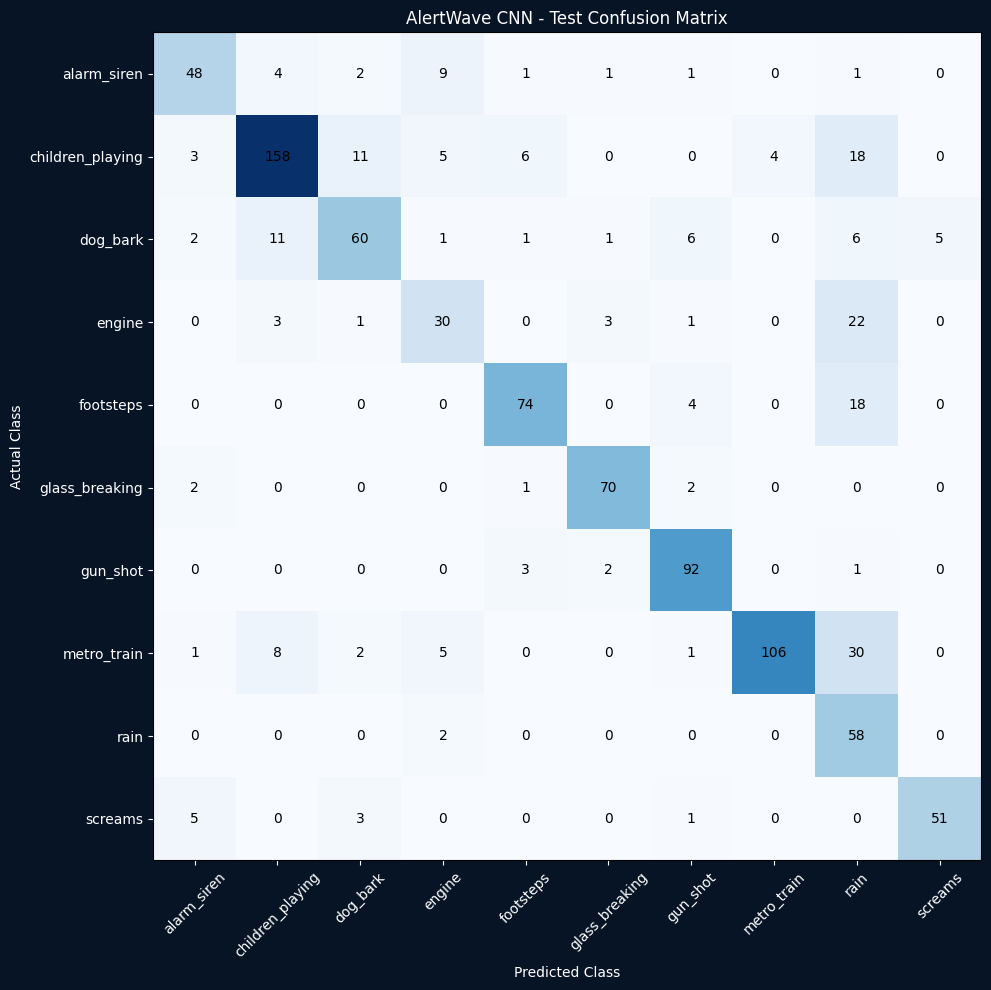


========== DOG BARK ANALYSIS ==========
Actual dog-bark test samples: 93
Correctly predicted dog barking: 60
Dog barking predicted as glass breaking: 1
Dog barking recall: 64.52 %

Incorrect dog-bark predictions:
Actual: dog_bark | Predicted: gun_shot | Dog score: 8.01 % | Glass score: 4.97 %
Actual: dog_bark | Predicted: children_playing | Dog score: 12.81 % | Glass score: 0.33 %
Actual: dog_bark | Predicted: children_playing | Dog score: 17.12 % | Glass score: 0.06 %
Actual: dog_bark | Predicted: children_playing | Dog score: 24.74 % | Glass score: 2.35 %
Actual: dog_bark | Predicted: engine | Dog score: 21.97 % | Glass score: 0.48 %
Actual: dog_bark | Predicted: gun_shot | Dog score: 21.19 % | Glass score: 12.19 %
Actual: dog_bark | Predicted: screams | Dog score: 3.14 % | Glass score: 0.01 %
Actual: dog_bark | Predicted: alarm_siren | Dog score: 21.0 % | Glass score: 13.85 %
Actual: dog_bark | Predicted: children_playing | Dog score: 5.83 % | Glass score: 0.91 %
Actual: dog_bark |

In [ ]:

# ============================================================
# ALERTWAVE - PART 3: MODEL EVALUATION
# ============================================================

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test accuracy:", round(test_accuracy * 100, 2), "%")
print("Test loss:", round(test_loss, 4))

# Predictions
test_probabilities = model.predict(
    X_test,
    batch_size=32,
    verbose=1
)

y_pred = np.argmax(test_probabilities, axis=1)

# Classification report
print("\nCLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(CLASSES)))
)

fig, ax = plt.subplots(figsize=(12, 10))

fig.patch.set_facecolor("#071426")
ax.set_facecolor("#10243d")

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

ax.set_title(
    "AlertWave CNN - Test Confusion Matrix",
    color="white"
)

ax.set_xlabel("Predicted Class", color="white")
ax.set_ylabel("Actual Class", color="white")

ax.tick_params(colors="white")

for text_item in ax.texts:
    text_item.set_color("black")

plt.tight_layout()
plt.show()

# ============================================================
# SPECIFIC DOG BARK VS GLASS BREAKING CHECK
# ============================================================

dog_index = CLASS_TO_INDEX["dog_bark"]
glass_index = CLASS_TO_INDEX["glass_breaking"]

dog_positions = np.where(y_test == dog_index)[0]

dog_predicted_as_glass = np.sum(
    y_pred[dog_positions] == glass_index
)

dog_total = len(dog_positions)

dog_correct = np.sum(
    y_pred[dog_positions] == dog_index
)

print("\n========== DOG BARK ANALYSIS ==========")

print("Actual dog-bark test samples:", dog_total)
print("Correctly predicted dog barking:", dog_correct)
print("Dog barking predicted as glass breaking:", dog_predicted_as_glass)

if dog_total > 0:
    print(
        "Dog barking recall:",
        round((dog_correct / dog_total) * 100, 2),
        "%"
    )

# Show examples where dog barking was classified incorrectly
wrong_dog_positions = [
    i for i in dog_positions
    if y_pred[i] != dog_index
]

print("\nIncorrect dog-bark predictions:")

for i in wrong_dog_positions[:15]:

    print(
        "Actual: dog_bark | Predicted:",
        CLASSES[y_pred[i]],
        "| Dog score:",
        round(test_probabilities[i][dog_index] * 100, 2),
        "% | Glass score:",
        round(test_probabilities[i][glass_index] * 100, 2),
        "%"
    )

# ============================================================
# SAVE CONFIGURATION
# ============================================================

config = {
    "sample_rate": SAMPLE_RATE,
    "duration": DURATION,
    "n_mels": N_MELS,
    "max_frames": MAX_FRAMES,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "classes": CLASSES,
    "normalization": "clip((power_to_db + 80) / 80, 0, 1)",
    "input_shape": list(model.input_shape)
}

CONFIG_PATH = PROJECT_DIR / "alertwave_config.json"

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=4)

print("\nModel saved:", MODEL_PATH)
print("Configuration saved:", CONFIG_PATH)

print("\nPart 3 completed.")


In [26]:
def analyze_audio(audio):

    print("\n========== ALERTWAVE FRONTEND DEBUG ==========")
    print("Received audio type:", type(audio))
    print("Received audio value:", repr(audio)[:1000])
    print("Is audio None?:", audio is None)

    if audio is None:
        return (
            "NO AUDIO RECEIVED BY FRONTEND",
            get_analytics_text(),
            create_analytics_chart()
        )

    return (
        "AUDIO RECEIVED SUCCESSFULLY",
        get_analytics_text(),
        create_analytics_chart()
    )

In [ ]:

# ============================================================
# ALERTWAVE - COMPLETE AI SOUND DETECTION DASHBOARD
# ============================================================

import os
import numpy as np
import librosa
import gradio as gr
import tensorflow as tf
import matplotlib.pyplot as plt

# ============================================================
# 1. LOAD TRAINED CNN MODEL
# ============================================================

MODEL_PATH = "/content/AlertWave/alertwave_cnn.keras"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "CNN model not found. Check the model path."
    )

model = tf.keras.models.load_model(MODEL_PATH)

print("AlertWave CNN model loaded successfully!")


# ============================================================
# 2. MODEL CONFIGURATION
# ============================================================

SAMPLE_RATE = 22050
DURATION = 4
N_MELS = 128
MAX_FRAMES = 128
N_FFT = 1024
HOP_LENGTH = 512

# Keep this order exactly the same as model training.

CLASS_NAMES = [
    "alarm_siren",
    "children_playing",
    "dog_bark",
    "engine",
    "footsteps",
    "glass_breaking",
    "gun_shot",
    "metro_train",
    "rain",
    "screams"
]

# Emergency alert categories.

ALERT_CLASSES = {
    "dog_bark",
    "alarm_siren",
    "screams",
    "scream",
    "glass_breaking"
}


# ============================================================
# 3. LOAD AUDIO
# ============================================================

def load_audio(audio_path):

    if audio_path is None:
        raise ValueError("No audio received.")

    if isinstance(audio_path, tuple):

        sample_rate, audio = audio_path

        audio = np.asarray(audio, dtype=np.float32)

        if audio.ndim == 2:
            audio = np.mean(audio, axis=1)

        if sample_rate != SAMPLE_RATE:
            audio = librosa.resample(
                audio,
                orig_sr=sample_rate,
                target_sr=SAMPLE_RATE
            )

    else:

        audio, _ = librosa.load(
            audio_path,
            sr=SAMPLE_RATE,
            mono=True
        )

    required_length = SAMPLE_RATE * DURATION

    if len(audio) < required_length:

        audio = np.pad(
            audio,
            (0, required_length - len(audio))
        )

    else:

        audio = audio[:required_length]

    return audio.astype(np.float32)


# ============================================================
# 4. FEATURE EXTRACTION
# ============================================================

def extract_features(audio):

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    mel_db = (mel_db + 80.0) / 80.0

    mel_db = np.clip(
        mel_db,
        0.0,
        1.0
    )

    if mel_db.shape[1] < MAX_FRAMES:

        padding = MAX_FRAMES - mel_db.shape[1]

        mel_db = np.pad(
            mel_db,
            ((0, 0), (0, padding))
        )

    else:

        mel_db = mel_db[:, :MAX_FRAMES]

    features = mel_db[..., np.newaxis]

    features = np.expand_dims(
        features,
        axis=0
    )

    return features.astype(np.float32)


# ============================================================
# 5. PREDICT SOUND AND GENERATE ALERT
# ============================================================

def classify_sound(audio_path):

    audio = load_audio(audio_path)

    features = extract_features(audio)

    predictions = model.predict(
        features,
        verbose=0
    )

    predicted_index = int(
        np.argmax(predictions[0])
    )

    predicted_class = CLASS_NAMES[predicted_index]

    confidence = float(
        predictions[0][predicted_index]
    )

    predicted_class = (
        predicted_class
        .strip()
        .lower()
        .replace(" ", "_")
    )

    print("\n========== ALERTWAVE PREDICTION ==========")

    top_indices = np.argsort(
        predictions[0]
    )[::-1][:3]

    for index in top_indices:

        print(
            CLASS_NAMES[index],
            ":",
            round(
                float(predictions[0][index]) * 100,
                2
            ),
            "%"
        )

    print("Predicted class:", predicted_class)
    print("Confidence:", round(confidence * 100, 2), "%")

    # Alert decision.
    if predicted_class in ALERT_CLASSES:

        result = "🚨 ALERT"
        alert_value = 1

    else:

        result = "✅ NOT ALERT"
        alert_value = 0

    return result, alert_value


# ============================================================
# 6. ANALYTICS
# ============================================================

def create_analytics(history):

    total = len(history)

    alerts = sum(history)

    not_alerts = total - alerts

    alert_percentage = (
        (alerts / total) * 100
        if total > 0 else 0
    )

    fig, ax = plt.subplots(figsize=(7, 4))

    categories = [
        "ALERT",
        "NOT ALERT"
    ]

    values = [
        alerts,
        not_alerts
    ]

    ax.bar(categories, values)

    ax.set_title("AlertWave Sound Analysis")
    ax.set_ylabel("Number of Recordings")

    ax.set_ylim(
        bottom=0,
        top=max(values + [1]) * 1.2
    )

    for i, value in enumerate(values):

        ax.text(
            i,
            value,
            str(value),
            ha="center",
            va="bottom"
        )

    plt.tight_layout()

    analytics_text = f"""
TOTAL RECORDINGS: {total}

ALERT COUNT: {alerts}

NOT ALERT COUNT: {not_alerts}

ALERT PERCENTAGE: {alert_percentage:.2f}%
"""

    return analytics_text, fig


# ============================================================
# 7. ANALYZE AUDIO
# ============================================================

def analyze_audio(audio_path, history):

    if history is None:
        history = []

    if audio_path is None:

        analytics_text, chart = create_analytics(history)

        return (
            "Please upload or record audio.",
            history,
            analytics_text,
            chart
        )

    try:

        result, alert_value = classify_sound(audio_path)

        history = history + [alert_value]

        analytics_text, chart = create_analytics(history)

        return (
            result,
            history,
            analytics_text,
            chart
        )

    except Exception as error:

        print("ERROR:", str(error))

        analytics_text, chart = create_analytics(history)

        return (
            f"Audio processing failed: {str(error)}",
            history,
            analytics_text,
            chart
        )


# ============================================================
# 8. RESET ANALYTICS
# ============================================================

def reset_analytics():

    history = []

    analytics_text, chart = create_analytics(history)

    return (
        "Upload or record audio to begin.",
        history,
        analytics_text,
        chart
    )


# ============================================================
# 9. DASHBOARD DESIGN
# ============================================================

custom_css = """
body {
    background-color: #101827;
}

.gradio-container {
    background-color: #101827 !important;
    color: white !important;
}

h1, h2, h3, p, label, span {
    color: white !important;
}

.result-box {
    text-align: center;
    font-size: 30px;
    font-weight: bold;
    padding: 25px;
    border-radius: 12px;
    background-color: #1e293b;
}
"""


# ============================================================
# 10. GRADIO INTERFACE
# ============================================================

with gr.Blocks(
    theme=gr.themes.Soft(),
    css=custom_css,
    title="AlertWave"
) as demo:

    history_state = gr.State([])

    gr.Markdown(
        """
        # 🌊 AlertWave

        ### AI-Based Environmental Sound Anomaly Detection
        ### and Emergency Location Alert System

        Detect environmental sounds using a trained CNN model.
        """
    )

    gr.Markdown("---")

    gr.Markdown("## 🎙️ Audio Detection")

    audio_input = gr.Audio(
        sources=["upload", "microphone"],
        type="filepath",
        label="Upload or Record Audio"
    )

    analyze_button = gr.Button(
        "🔍 ANALYZE SOUND",
        variant="primary"
    )

    result_output = gr.Markdown(
        "Upload or record audio to begin.",
        elem_classes=["result-box"]
    )

    gr.Markdown("---")

    gr.Markdown("## 📊 Analytics Dashboard")

    analytics_output = gr.Textbox(
        label="Analysis Summary",
        interactive=False
    )

    chart_output = gr.Plot(
        label="Alert Statistics"
    )

    analyze_button.click(
        fn=analyze_audio,
        inputs=[
            audio_input,
            history_state
        ],
        outputs=[
            result_output,
            history_state,
            analytics_output,
            chart_output
        ]
    )

    gr.Markdown("---")

    reset_button = gr.Button(
        "🔄 RESET ANALYTICS"
    )

    reset_button.click(
        fn=reset_analytics,
        inputs=[],
        outputs=[
            result_output,
            history_state,
            analytics_output,
            chart_output
        ]
    )

    gr.Markdown(
        """
        ---

        ### 🚨 Emergency Alert Categories

        - Dog barking
        - Alarm siren
        - Screams
        - Glass breaking

        All other sound categories are classified as NOT ALERT.

        **Note:** AlertWave is a project prototype and should not
        be relied on as the only means of emergency detection.
        """
    )


# ============================================================
# 11. LAUNCH
# ============================================================

demo.launch(
    share=True,
    debug=True
)


AlertWave CNN model loaded successfully!
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://efeb1e9d25bf4c95b8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



========== ALERTWAVE PREDICTION ==========
dog_bark : 87.2 %
children_playing : 5.84 %
screams : 2.45 %
Predicted class: dog_bark
Confidence: 87.2 %

========== ALERTWAVE PREDICTION ==========
glass_breaking : 55.71 %
footsteps : 43.33 %
children_playing : 0.5 %
Predicted class: glass_breaking
Confidence: 55.71 %

========== ALERTWAVE PREDICTION ==========
glass_breaking : 55.71 %
footsteps : 43.33 %
children_playing : 0.5 %
Predicted class: glass_breaking
Confidence: 55.71 %

========== ALERTWAVE PREDICTION ==========
footsteps : 55.8 %
glass_breaking : 43.27 %
children_playing : 0.68 %
Predicted class: footsteps
Confidence: 55.8 %

========== ALERTWAVE PREDICTION ==========
children_playing : 56.8 %
dog_bark : 20.52 %
alarm_siren : 10.63 %
Predicted class: children_playing
Confidence: 56.8 %

========== ALERTWAVE PREDICTION ==========
dog_bark : 51.86 %
screams : 22.01 %
children_playing : 20.99 %
Predicted class: dog_bark
Confidence: 51.86 %

========== ALERTWAVE PREDICTION =======